
# Resistive Respiration Sensor

## Data Processing

This notebook contains the processing and visualization of the strain sensor measurements recorded during the laboratory 1. 




## 1 Sensor Test
# 1.1 Voltage Divider & Resistance–Output Relation


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# Fixed Resistor
R1 = 10000  

# Maximum value of 10-bit ADC
max_adc = 1023 

# Convert ADC values to sensor resistance
def adc_to_resistance(adc):
    return R1 * adc / (max_adc - adc)

def save_current_plot(filename="plot.png", dpi=300):
    # bbox_inches='tight' ensures that labels and titles are not cut off
    plt.savefig(filename, dpi=dpi, bbox_inches='tight')
    
    # Print the absolute path where it was saved to help you find it
    save_path = os.path.abspath(filename)
    print(f"Success! Plot saved to: {save_path}")

: 

# 1.2 20% Strain – Pre-Conditioning

**Note:** Four cycles were recorded instead of three.


In [ ]:
# Load pre-conditoning data
adc_ex2 = np.loadtxt("ex2rec2.txt")  
resistance_ex2 = adc_to_resistance(adc_ex2)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_ex2, linewidth=1)

plt.xlabel("Sample Number")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("20% Strain – Pre-Conditioning")
plt.ylim(600, 1500) # Scaling y limit axis
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.2.png", dpi=300)
plt.show()

: 


## 1.3 Conditioning & 20% Strain – Post-Conditioning


<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')
<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')


Success! Plot saved to: /drive/notebooks/task1.3.1.png


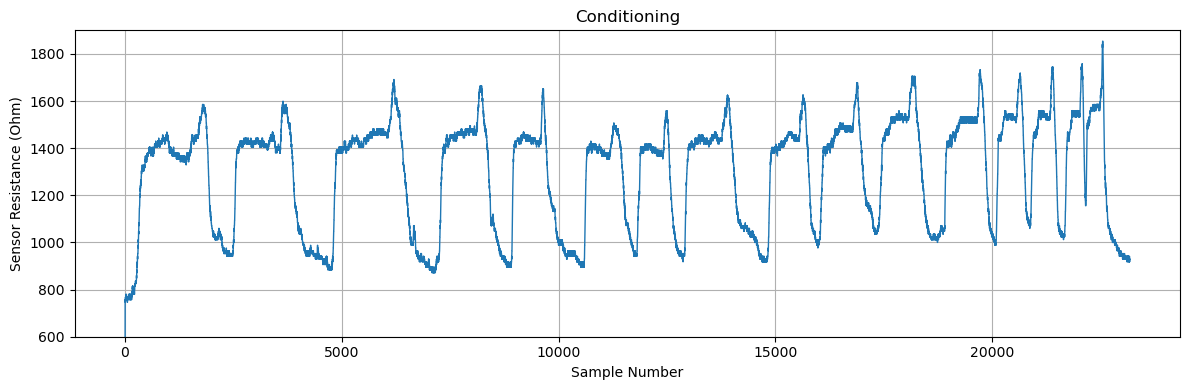

In [ ]:
# Load conditioning data
adc_cond = np.loadtxt("ex3rec0_cond.txt")  
resistance_cond = adc_to_resistance(adc_cond)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_cond, linewidth=1)

plt.xlabel("Sample Number")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("Conditioning")
plt.ylim(600, 1900) # Scaling y limit axis 
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.3.1.png", dpi=300)
plt.show()


<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')
<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')


Success! Plot saved to: /drive/notebooks/task1.3.2.png


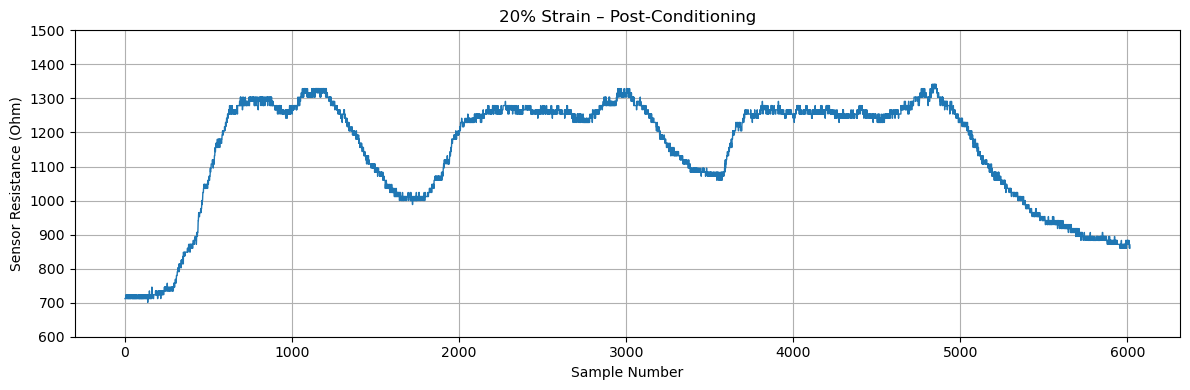

In [ ]:
# Load post-conditoning data
adc_ex3 = np.loadtxt("ex3rec1.txt")  
resistance_ex3 = adc_to_resistance(adc_ex3)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_ex3[:-1], linewidth=1) # Exclude final sample due to a recording artifact

plt.xlabel("Sample Number")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("20% Strain – Post-Conditioning")
plt.ylim(600, 1500)  # Scaling y limit axis
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.3.2.png", dpi=300)
plt.show()


## 1.4 Strain-Dependent Sensor σ & Calibration Curve


<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')
<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')


Success! Plot saved to: /drive/notebooks/task1.4.1.png


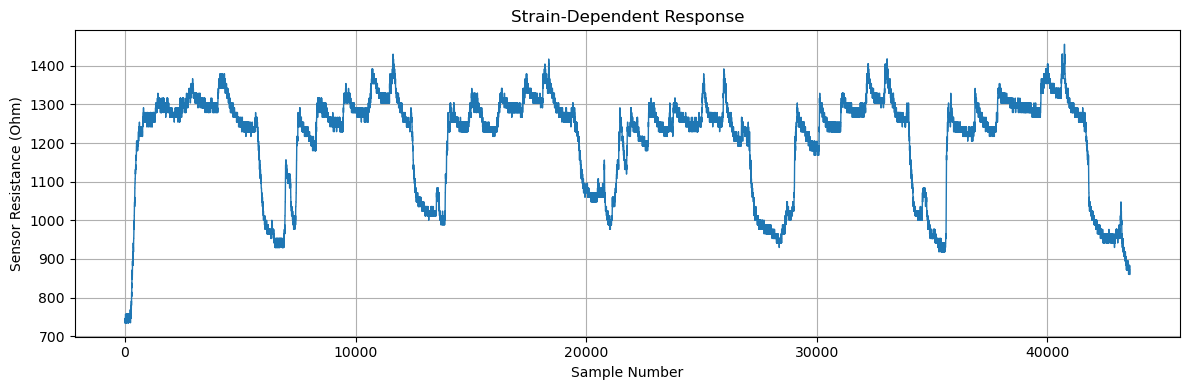

In [ ]:
# Load strain dependent data
adc_ex4 = np.loadtxt("ex4rec1.txt")
resistance_ex4 = adc_to_resistance(adc_ex4)

# Plot
plt.figure(figsize=(12, 4))
plt.plot(resistance_ex4, linewidth=1)

plt.xlabel("Sample Number")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("Strain-Dependent Response")
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.4.1.png", dpi=300)
plt.show()

**Note:** A moving average filter is applied to reduce signal noise.

<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')
<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')


Success! Plot saved to: /drive/notebooks/task1.4.2.png


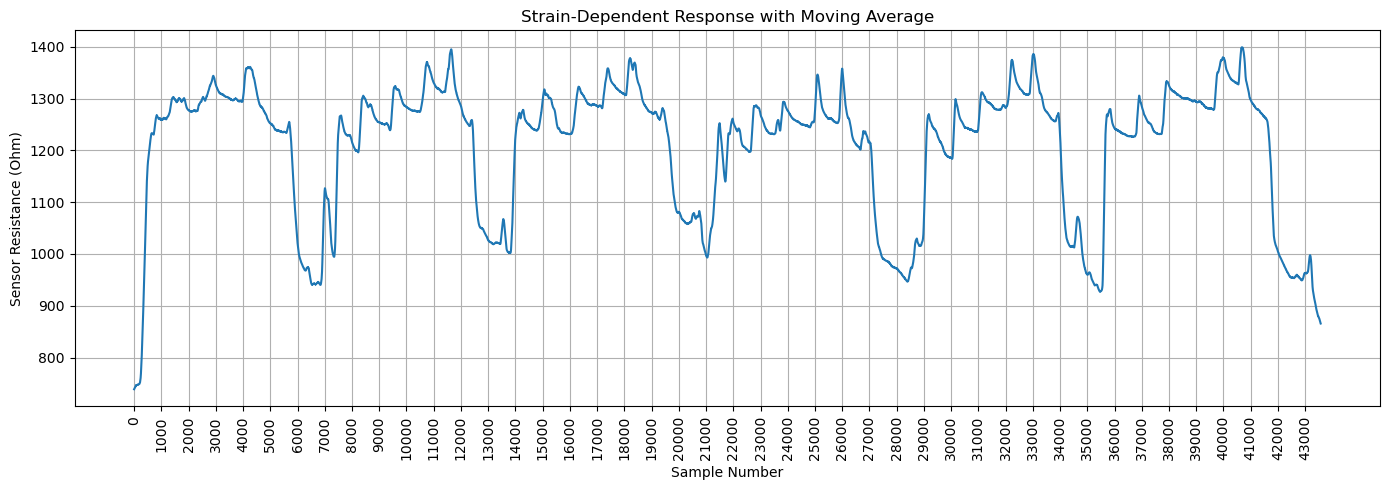

In [ ]:
# Apply moving average filter
window_size = 100
weights = np.ones(window_size) / window_size

resistance_ex4_filtered = np.convolve( 
    np.pad(resistance_ex4, (window_size // 2, window_size // 2), mode="edge"), weights, mode="valid"
)[:len(resistance_ex4)]

# Plot filtered data
plt.figure(figsize=(14, 5))
plt.plot(resistance_ex4_filtered, linewidth=1.5)
plt.xticks(np.arange(0, len(resistance_ex4_filtered), 1000), rotation=90)

plt.xlabel("Sample Number")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("Strain-Dependent Response with Moving Average")
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.4.2.png", dpi=300)
plt.show()

**Note:** Intervals were manually selected to calculate the mean resistance and standard deviation.

In [ ]:
# Manually selected intervals for three repetitions (cycle 3, 5 and 6) 
data = np.loadtxt("ex4rec1.txt")

intervals_rep1 = [
    (13100, 13400),
    (14100, 14400),
    (14950, 15200),
    (16250, 16500),
    (17500, 17800),
    (18800, 19100),
    (20100, 20400)
]

intervals_rep2 = [
    (27800, 28100),
    (29250, 29500),
    (30350, 30650),
    (31300, 31600),
    (32450, 32750),
    (33400, 33700),
    (34300, 34500)
]
intervals_rep3 = [
    (35100, 35400),
    (36000, 36300),
    (37200, 37500),
    (38300, 38600),
    (39900, 40200),
    (41000, 41300),
    (42300, 42600)
]

# Calculate mean resistance and standard deviation 
all_intervals = [intervals_rep1, intervals_rep2, intervals_rep3]

for rep, intervals in enumerate(all_intervals, start=1):
    #print(f"\nRepetition {rep}")

    for i, (start, end) in enumerate(intervals, start=1):
        resistance_interval = resistance_ex4[start:end]

        mean_resistance = np.mean(resistance_interval)
        std_resistance = np.std(resistance_interval, ddof=1)
        #print(f"Interval {i}: Mean = {mean_resistance:.2f} Ω, SD = {std_resistance:.2f} Ω")

# Calculate overall mean and standard deviation 
mean_values = []
std_values = []

for i in range(7):
    samples = np.concatenate([
        resistance_ex4[start:end]
        for intervals in all_intervals
        for start, end in [intervals[i]]
    ])

    mean_values.append(np.mean(samples))
    std_values.append(np.std(samples, ddof=1))

    print(f"Interval {i+1}: Mean = {mean_values[-1]:.2f} Ω, SD = {std_values[-1]:.2f} Ω")


Interval 1: Mean = 979.60 Ω, SD = 32.14 Ω
Interval 2: Mean = 1250.00 Ω, SD = 18.08 Ω
Interval 3: Mean = 1264.01 Ω, SD = 29.44 Ω
Interval 4: Mean = 1301.52 Ω, SD = 13.43 Ω
Interval 5: Mean = 1335.37 Ω, SD = 24.98 Ω
Interval 6: Mean = 1277.00 Ω, SD = 10.59 Ω
Interval 7: Mean = 1011.24 Ω, SD = 45.47 Ω


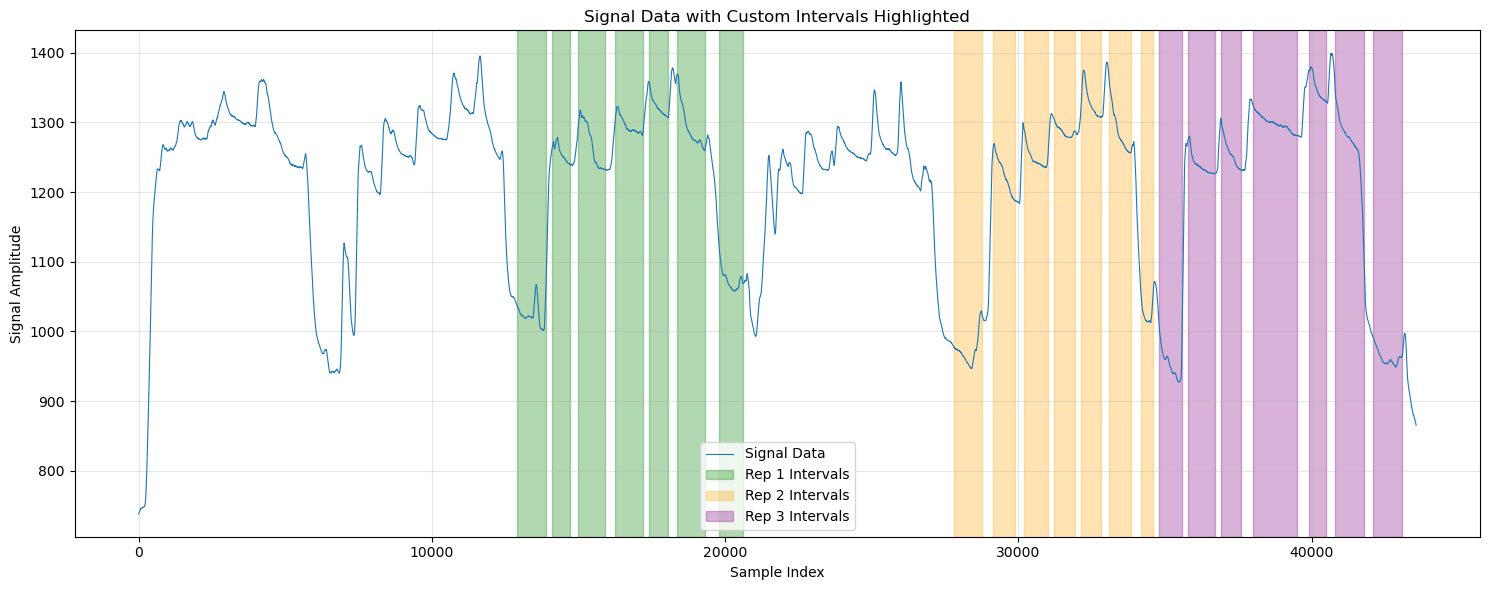

Interval 1: Mean = 985.42 Ω, SD = 37.48 Ω
Interval 2: Mean = 1239.66 Ω, SD = 24.30 Ω
Interval 3: Mean = 1259.55 Ω, SD = 27.08 Ω
Interval 4: Mean = 1295.23 Ω, SD = 13.67 Ω
Interval 5: Mean = 1334.12 Ω, SD = 23.35 Ω
Interval 6: Mean = 1283.53 Ω, SD = 39.65 Ω
Interval 7: Mean = 1013.05 Ω, SD = 51.89 Ω


In [ ]:
#New selected windows 
intervals_rep1 = [
    (12900, 13900),
    (14100, 14700),
    (15000, 15900),
    (16250, 17200),
    (17400, 18050),
    (18350, 19300),
    (19800, 20600)
]

intervals_rep2 = [
    (27800, 28750),
    (29150, 29900),
    (30200, 31000),
    (31225, 31925),
    (32125, 32825),
    (33100, 33850),
    (34200, 34600)
]

intervals_rep3 = [
    (34800, 35600),
    (35800, 36700),
    (36900, 37600),
    (38000, 39500),
    (39900, 40500),
    (40800, 41800),
    (42100, 43100)
]

# Create the plot
plt.figure(figsize=(15, 6))
plt.plot(resistance_ex4_filtered, label="Signal Data", color='#1f77b4', linewidth=0.8)

# Mark the intervals using shaded regions (axvspan) for visual clarity
for i, (start, end) in enumerate(intervals_rep1):
    label = "Rep 1 Intervals" if i == 0 else None
    plt.axvspan(start, end, color='green', alpha=0.3, label=label)

for i, (start, end) in enumerate(intervals_rep2):
    label = "Rep 2 Intervals" if i == 0 else None
    plt.axvspan(start, end, color='orange', alpha=0.3, label=label)

for i, (start, end) in enumerate(intervals_rep3):
    label = "Rep 3 Intervals" if i == 0 else None
    plt.axvspan(start, end, color='purple', alpha=0.3, label=label)

plt.title("Signal Data with Custom Intervals Highlighted")
plt.xlabel("Sample Index")
plt.ylabel("Signal Amplitude")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate mean resistance and standard deviation 
all_intervals = [intervals_rep1, intervals_rep2, intervals_rep3]

for rep, intervals in enumerate(all_intervals, start=1):
    #print(f"\nRepetition {rep}")

    for i, (start, end) in enumerate(intervals, start=1):
        resistance_interval = resistance_ex4[start:end]

        mean_resistance = np.mean(resistance_interval)
        std_resistance = np.std(resistance_interval, ddof=1)
        #print(f"Interval {i}: Mean = {mean_resistance:.2f} Ω, SD = {std_resistance:.2f} Ω")

# Calculate overall mean and standard deviation 
mean_values = []
std_values = []

for i in range(7):
    samples = np.concatenate([
        resistance_ex4[start:end]
        for intervals in all_intervals
        for start, end in [intervals[i]]
    ])

    mean_values.append(np.mean(samples))
    std_values.append(np.std(samples, ddof=1))

    print(f"Interval {i+1}: Mean = {mean_values[-1]:.2f} Ω, SD = {std_values[-1]:.2f} Ω")


**Note:** The seven manually selected intervals correspond to the following strain levels

- **Interval 1:** 0% strain – Extension
- **Interval 2:** 10% strain – Extension
- **Interval 3:** 20% strain – Extension
- **Interval 4:** 30% strain – Extension
- **Interval 5:** 20% strain – Recovery
- **Interval 6:** 10% strain – Recovery
- **Interval 7:** 0% strain – Recovery

<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The x parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(x) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')
<ipython-input-7-6c978d5f6e15>:18: MatplotlibDeprecationWarning: The y parameter as float was deprecated in Matplotlib 3.10 and will be removed in 3.12. Use int(y) instead.
  plt.savefig(filename, dpi=dpi, bbox_inches='tight')


Success! Plot saved to: /drive/notebooks/task1.4.3.png


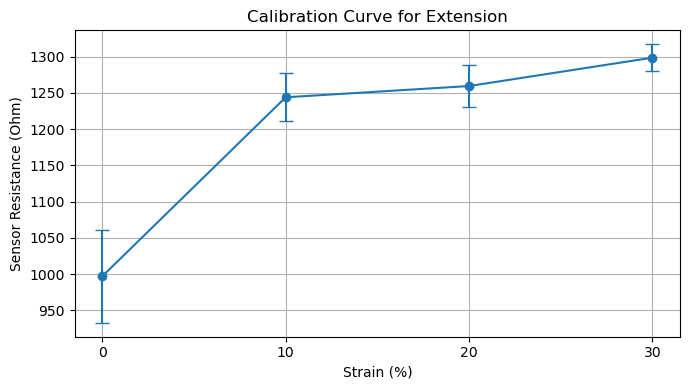

In [ ]:
# Plot calibration curve for extension
strain = np.array([0, 10, 20, 30])

plt.figure(figsize=(7, 4))
plt.errorbar(
    strain,
    mean_values[:4],
    yerr=std_values[:4],
    fmt="o-",
    capsize=5,
    linewidth=1.5
)

plt.xlabel("Strain (%)")
plt.ylabel("Sensor Resistance (Ohm)")
plt.title("Calibration Curve for Extension")
plt.xticks(strain)
plt.grid(True)
plt.tight_layout()
save_current_plot(filename="task1.4.3.png", dpi=300)
plt.show()

# 2 Wearable Data Collection
## 2.1 Variation of Sensor Position & Tightness


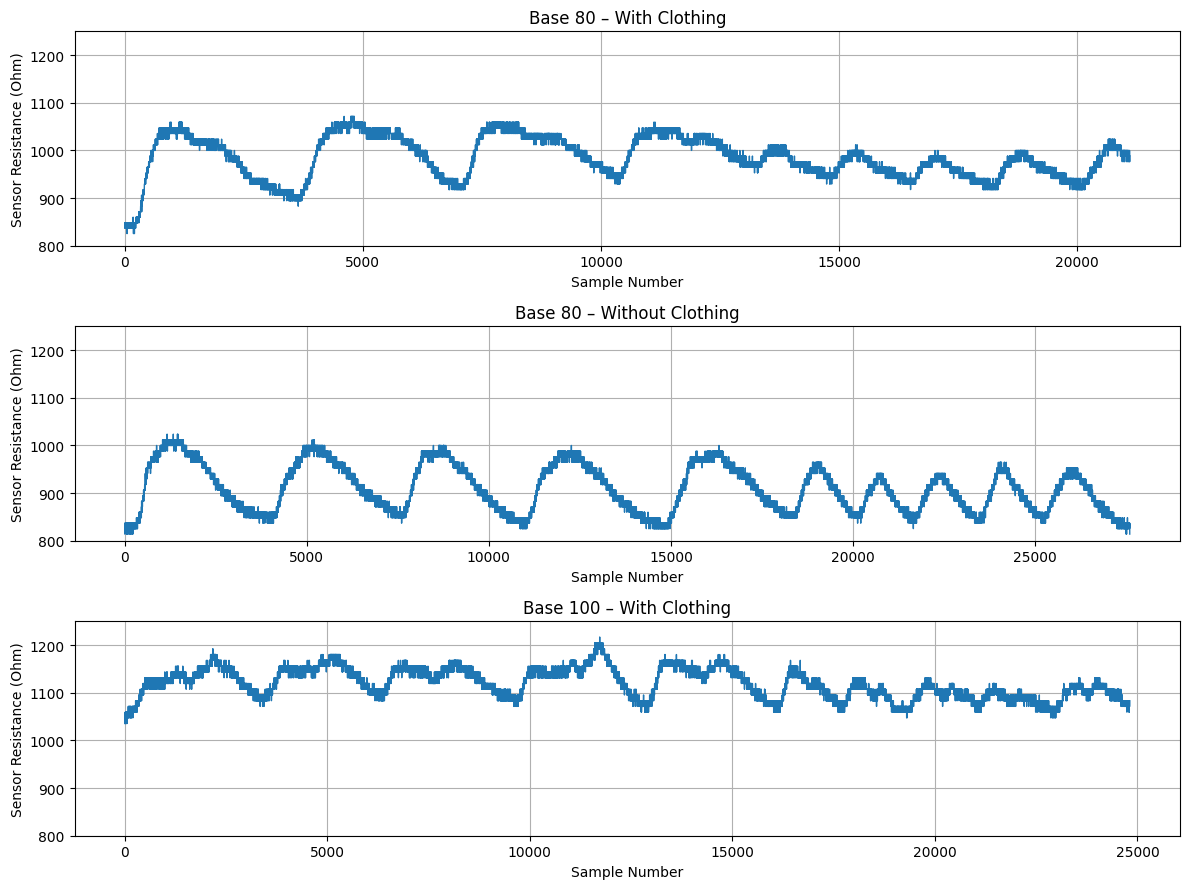

In [ ]:
# Load wearable data
adc_80_cloth = np.loadtxt("ex5_base80_cloth.txt")
adc_80_nocloth = np.loadtxt("ex5_base80_nocloth.txt")
adc_100_cloth = np.loadtxt("ex5_base100_cloth.txt")

# Convert ADC values to sensor resistance
resistance_80_cloth = adc_to_resistance(adc_80_cloth)
resistance_80_nocloth = adc_to_resistance(adc_80_nocloth)
resistance_100_cloth = adc_to_resistance(adc_100_cloth)

# Plot 
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

axes[0].plot(resistance_80_cloth[:-1], linewidth=1)
axes[0].set_title("Base 80 – With Clothing")

axes[1].plot(resistance_80_nocloth, linewidth=1)
axes[1].set_title("Base 80 – Without Clothing")

axes[2].plot(resistance_100_cloth, linewidth=1)
axes[2].set_title("Base 100 – With Clothing")

for ax in axes:
    ax.set_xlabel("Sample Number")
    ax.set_ylabel("Sensor Resistance (Ohm)")
    ax.grid(True)
    ax.set_ylim(800, 1250)


plt.tight_layout()
plt.show()


## 2.2 Raw Data Comparison of Breathing Depth


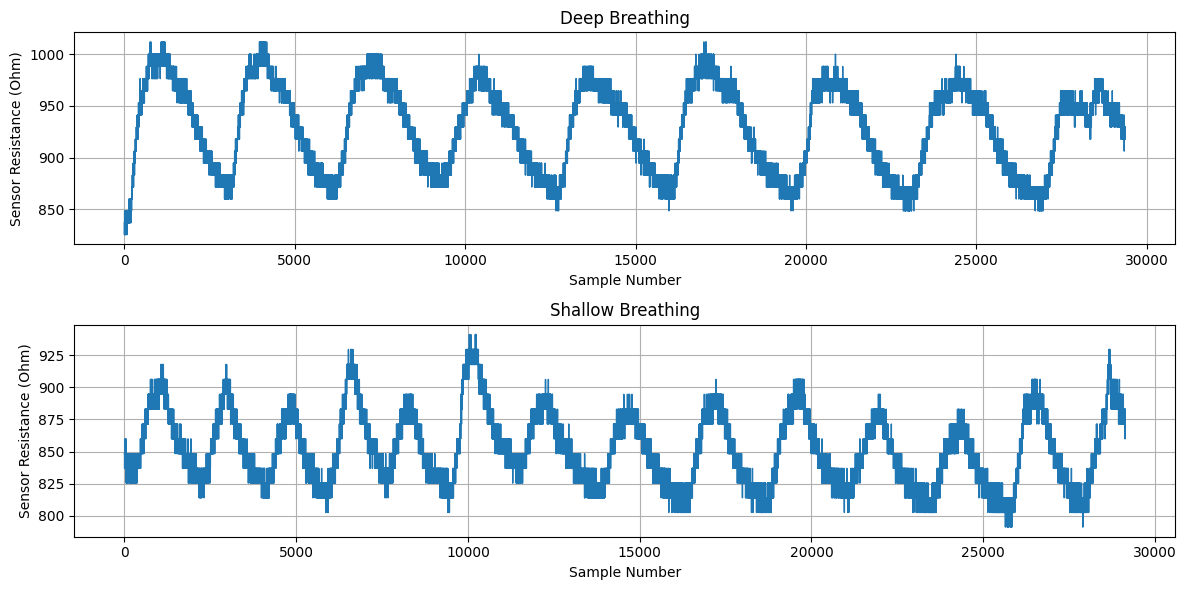

In [ ]:
# Load breathing data
adc_deep = np.loadtxt("ex6_deep.txt")
adc_shallow = np.loadtxt("ex6_shallow.txt")

# Convert ADC values to sensor resistance
resistance_deep = adc_to_resistance(adc_deep)
resistance_shallow = adc_to_resistance(adc_shallow)

# Plot
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(resistance_deep, linewidth=1)
axes[0].set_title("Deep Breathing")

axes[1].plot(resistance_shallow, linewidth=1)
axes[1].set_title("Shallow Breathing")

for ax in axes:
    ax.set_xlabel("Sample Number")
    ax.set_ylabel("Sensor Resistance (Ohm)")
    ax.grid(True)

plt.tight_layout()
plt.show()


## 2.3 Moving Average Filter & Measurement Analysis


In [ ]:
# Apply moving average filter
window_size = 100
weights = np.ones(window_size) / window_size

resistance_deep_filtered = np.convolve(
    np.pad(resistance_deep, (window_size // 2, window_size // 2), mode="edge"),
    weights, mode="valid"
)[:len(resistance_deep)]

resistance_shallow_filtered = np.convolve(
    np.pad(resistance_shallow, (window_size // 2, window_size // 2), mode="edge"),
    weights, mode="valid"
)[:len(resistance_shallow)]

In [ ]:
# Detect breathing peaks
peaks_deep, _ = find_peaks(
    resistance_deep_filtered,
    prominence=30,
    distance=1000
)

peaks_shallow, _ = find_peaks(
    resistance_shallow_filtered,
    prominence=20,
    distance=1000
)

print(f"Deep breathing: {len(peaks_deep)} peaks")
print(f"Shallow breathing: {len(peaks_shallow)} peaks")

Deep breathing: 9 peaks
,Shallow breathing: 14 peaks


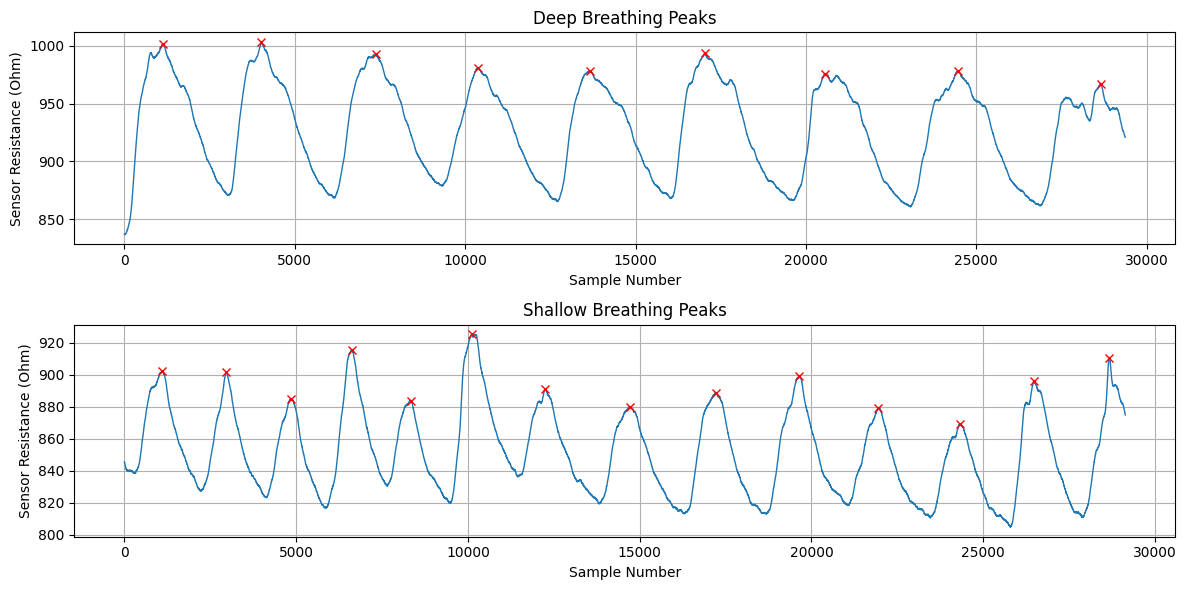

In [ ]:
# Plot filtered signals and detected breathing peaks
fig, axes = plt.subplots(2, 1, figsize=(12, 6))

axes[0].plot(resistance_deep_filtered, linewidth=1)
axes[0].plot(peaks_deep, resistance_deep_filtered[peaks_deep], "rx")
axes[0].set_title("Deep Breathing Peaks")

axes[1].plot(resistance_shallow_filtered, linewidth=1)
axes[1].plot(peaks_shallow, resistance_shallow_filtered[peaks_shallow], "rx")
axes[1].set_title("Shallow Breathing Peaks")

for ax in axes:
    ax.set_xlabel("Sample Number")
    ax.set_ylabel("Sensor Resistance (Ohm)")
    ax.grid(True)

plt.tight_layout()
plt.show()